#Day 35 Prediksi Korban Titanic dengan Decission Tree & Visualisai

Salah satu kelebihan **Decision Tree** adalah ia bisa kita "lihat" — kita bisa menggambar pohonnya dan membaca aturan-aturan keputusannya seperti diagram alur.

Di notebook ini kita melatih Decision Tree pada data Titanic, **menggambar pohonnya**, lalu mempelajari bagaimana `max_depth` mengontrol keseimbangan antara terlalu sederhana dan **overfitting**.


> 🎯 **Tujuan Pembelajaran**
> - Melatih `DecisionTreeClassifier` dan **menggambarnya** dengan `plot_tree`.
> - Memahami **overfitting** lewat perbandingan akurasi **train vs test**.
> - Melihat efek `max_depth` terhadap performa.
> - Membaca **feature importance** & **confusion matrix**.

## Tentang Dataset


Memakai **Titanic Dataset** untuk memprediksi siapa yang selamat.

- **Sumber:** [Kaggle — yasserh/titanic-dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset)
- **Target:** kolom `Survived` (1 = selamat, 0 = tidak).

| Kolom | Arti |
|-------|------|
| `Survived` | **Label**: 1 = selamat, 0 = tidak |
| `Pclass` | Kelas tiket (1/2/3) |
| `Sex` | Jenis kelamin |
| `Age` | Usia |
| `SibSp` | Jumlah saudara/pasangan di kapal |
| `Parch` | Jumlah orang tua/anak di kapal |
| `Fare` | Harga tiket |
| `Embarked` | Pelabuhan naik (C/Q/S) |

## Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

## Import Dataset

In [3]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d yasserh/titanic-dataset
!unzip titanic-dataset.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/yasserh/titanic-dataset
License(s): CC0-1.0
100% 22.0k/22.0k [00:00<00:00, 41.8MB/s]

Archive:  titanic-dataset.zip
  inflating: Titanic-Dataset.csv     


## Eksplorasi Awal Dataset

In [4]:
df = pd.read_csv('/content/Titanic-Dataset.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [11]:
print("Nama kolom:", list(df.columns))
print(f'Banyak baris: {df.shape[0]}')
print(f'Banyak kolom: {df.shape[1]}')
print(f'Banyak nilai null: {df.isna().sum().sum()}')
print(df.isnull().sum())
df.info()

Nama kolom: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Banyak baris: 891
Banyak kolom: 12
Banyak nilai null: 866
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   

In [10]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


**Interpretasi:**
- Ada campuran kolom numerik & teks, serta beberapa kolom yang tidak berguna untuk model (`Name`, `Ticket`, `Cabin`, `PassengerId`).
- `Age` & `Embarked` punya nilai kosong yang harus ditangani.
- `Age` banyak kosong, `Embarked` sedikit, `Cabin` sangat banyak kosong (akan kita buang). Kita perlu imputasi untuk Age & Embarked

## Feature Engineering dan Cleaning Dataset

In [12]:
data = df.copy()

In [13]:
#Imputasi
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])
data['Fare'] = data['Fare'].fillna(data['Fare'].median())

In [14]:
# Encoding data kategorical
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})
data['Embarked'] = data['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

In [15]:
fitur = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
data = data[fitur + ['Survived']].dropna()

In [19]:
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [18]:
print(f'Banyak baris: {data.shape[0]}')
print(f'Banyak kolom: {data.shape[1]}')
print(f'Banyak nilai null: {data.isna().sum().sum()}')
data.head()

Banyak baris: 891
Banyak kolom: 8
Banyak nilai null: 0


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,3,0,22.0,1,0,7.2500,0,0
1,1,1,38.0,1,0,71.2833,1,1
2,3,1,26.0,0,0,7.9250,0,1
3,1,1,35.0,1,0,53.1000,0,1
4,3,0,35.0,0,0,8.0500,0,0


Interpretasi:
- Pertahankan 7 fitur, isi Age dengan median dan Embarked dengan modus, lalu ubah `Sex`/`Embarked` menjadi angka. Data kini sepenuhnya numerik & bebas missing.

## Eksploratory Data Analysis dan Visualization

### a) Tingkat Keselamatan Penumpang Berdasarkan Jenis Kelamin

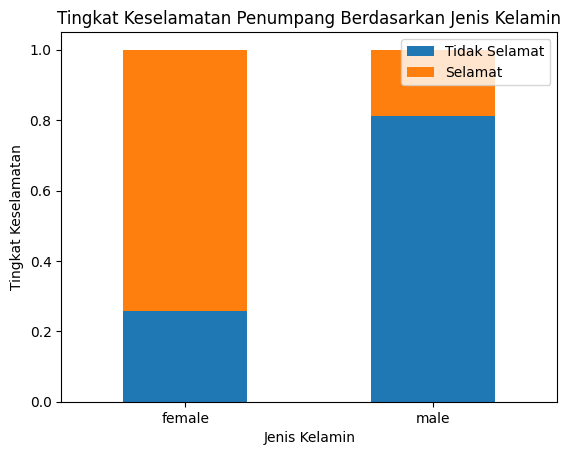

In [20]:
ct = pd.crosstab(df['Sex'], df['Survived'], normalize="index")
ct.plot(kind='bar', stacked=True)
plt.title('Tingkat Keselamatan Penumpang Berdasarkan Jenis Kelamin')
plt.xlabel('Jenis Kelamin')
plt.ylabel('Tingkat Keselamatan')
plt.xticks(rotation=0)
plt.legend(['Tidak Selamat', 'Selamat'])
plt.show()

**Interpretasi:**

- Penumpang Perempuan (female):
  - Tingkat Selamat (warna oranye) sangat tinggi, yaitu sekitar 74%.  
  - Tingkat Tidak Selamat (warna biru) jauh lebih kecil, yakni sekitar 26%.   

- Penumpang Laki-laki (male):
  - Sebaliknya, tingkat Tidak Selamat (warna biru) sangat mendominasi, yaitu sekitar 81%.   
  - Tingkat Selamat (warna oranye) sangat rendah, hanya sekitar 19%
  
Kesimpulan:

- Grafik ini menunjukkan ketimpangan yang sangat drastis dalam peluang keselamatan antara kedua jenis kelamin, di mana penumpang perempuan jauh lebih dominan selamat (sekitar 74%) sementara mayoritas penumpang laki-laki tidak selamat (sekitar 81%), yang umumnya disebabkan oleh kebijakan evakuasi darurat saat itu

### b) Tingkat Keselamatan Berdasarkan Kelas Tiket

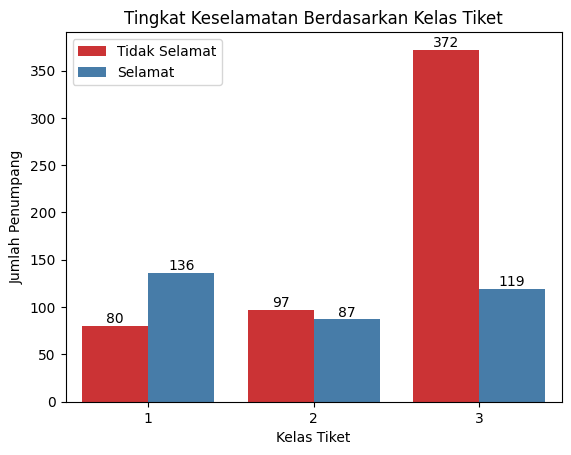

In [23]:
ax = sns.countplot(data=df, x='Pclass', hue='Survived', palette='Set1')
plt.title('Tingkat Keselamatan Berdasarkan Kelas Tiket')
plt.xlabel('Kelas Tiket')
plt.ylabel('Jumlah Penumpang')
plt.legend(['Tidak Selamat', 'Selamat'])
for i in ax.containers:
    ax.bar_label(i,)
plt.show()

**Interpretasi:**

- Kelas 1 (Kelas Atas / Utama):
  - Jumlah penumpang yang Selamat (136 orang) lebih tinggi daripada yang Tidak Selamat (80 orang).   
  - Menunjukkan bahwa penumpang kelas utama mendapatkan prioritas akses dan kemudahan evakuasi yang jauh lebih baik.

- Kelas 2 (Kelas Menengah):
  - Jumlahnya relatif seimbang, dengan korban Tidak Selamat (97 orang) sedikit lebih banyak dibandingkan yang Selamat (87 orang).   

- Kelas 3 (Kelas Bawah / Ekonomi):
  - Menunjukkan ketimpangan yang paling ekstrem dan memprihatinkan. Mayoritas besar penumpang, yaitu 372 orang, tidak selamat, sementara yang berhasil selamat hanya 119 orang.   
  
Kesimpulan Utama:
  - Grafik ini secara jelas menggambarkan adanya ketimpangan sosial-ekonomi dalam prosedur keselamatan darurat.
  - Penumpang kelas bawah tidak hanya mendominasi jumlah korban jiwa secara masif, tetapi juga memperlihatkan bahwa posisi kelas sosial sangat menentukan peluang bertahan hidup seseorang dalam bencana tersebut.   

### c) Distribusi Usia Berdasarkan Keselamatan

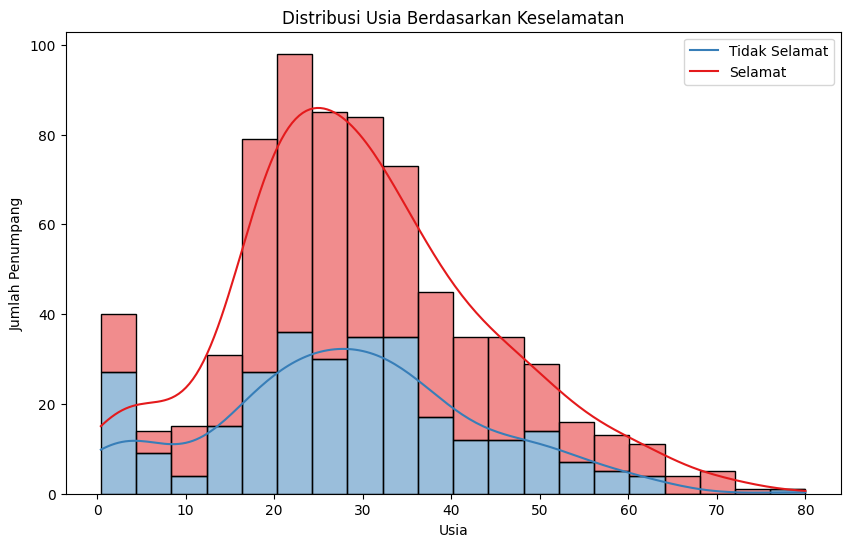

In [25]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Age', hue='Survived', multiple='stack', palette='Set1',kde=True)
plt.title('Distribusi Usia Berdasarkan Keselamatan')
plt.xlabel('Usia')
plt.ylabel('Jumlah Penumpang')
plt.legend(['Tidak Selamat', 'Selamat'])
plt.show()

**Interpretasi:**

- Dominasi Usia Produktif (17–35 tahun):
  - Jumlah total penumpang terbanyak berada pada rentang usia ini.   
  - Oleh karena itu, jumlah korban yang Selamat (area merah) terlihat paling tinggi mendominasi pada kelompok usia sekitar 20 hingga 35 tahun.   

- Prioritas Anak di Bawah 5 Tahun:
  - Pada kelompok usia paling dini (0–5 tahun di bagian paling kiri grafik), proporsi penumpang yang Selamat tampak jauh lebih mendominasi dibandingkan yang tidak selamat.   
  - Hal ini memperkuat bukti bahwa anak-anak balita benar-benar diberikan prioritas utama dalam proses evakuasi darurat.   
  
Kesimpulan Utama:

  - Grafik ini menunjukkan bahwa selain faktor gender dan kelas sosial, faktor usia juga sangat memengaruhi peluang keselamatan, di mana anak-anak usia di bawah 5 tahun mendapatkan prioritas penyelamatan yang tinggi, sementara kelompok usia produktif mendominasi jumlah orang yang berhasil diselamatkan karena faktor demografi.   

## Preprocessing ( Split Data )

In [26]:
#Split Data
X = data[fitur]
y = data['Survived']

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

In [31]:
print(f'Banyak data train: {X_train.shape}')
print(f'Banyak data test: {X_test.shape}')

Banyak data train: (712, 7)
Banyak data test: (179, 7)


**Interpretasi:**

- Data Latih (Train) (712, 7):

  - Terdapat 712 baris data dengan 7 kolom (fitur) yang digunakan oleh model machine learning untuk belajar mengenali pola. Porsi ini mencakup sekitar 80% dari keseluruhan data.

- Data Uji (Test) (179, 7):

  - Terdapat 179 baris data dengan 7 kolom (fitur) yang disisihkan dan digunakan untuk menguji seberapa baik model dalam memprediksi data baru yang belum pernah dilihat sebelumnya (mencakup sekitar 20% dari total data).

Kesimpulan:
- Pembagian data ini menggunakan rasio standar yang ideal (sekitar 80:20) dari total keseluruhan 891 data dengan 7 variabel/kolom.

## Modelling

In [37]:
dt_md_3 = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_md_3.fit(X_train, y_train)
y_pred = dt_md_3.predict(X_test)


print(f'Akurasi train: {dt_md_3.score(X_train, y_train):.2f}')
print(f'Akurasi test: {accuracy_score(y_test, y_pred):.2f}')

Akurasi train: 0.83
Akurasi test: 0.79


**Interpretasi:**

- Akurasi Train (0.83 atau 83%): Model berhasil mengenali dan menebal pola dengan benar sebesar 83% pada data latihan yang digunakan untuk ia belajar.

- Akurasi Test (0.79 atau 79%): Model berhasil memprediksi dengan benar sebesar 79% saat diuji pada data baru yang belum pernah dilihat sebelumnya.

## Visualization Create Tree

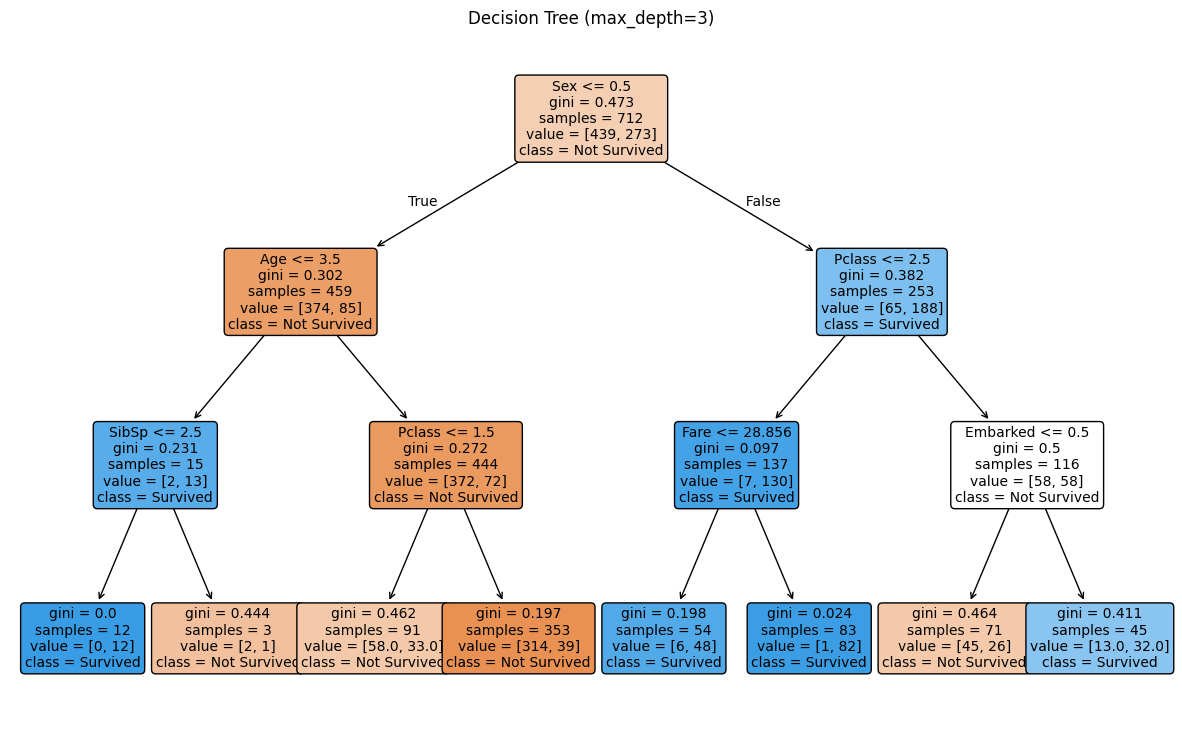

In [38]:
plt.figure(figsize=(15,9))

plot_tree(dt_md_3,
          feature_names=X_train.columns,
          class_names=['Not Survived', 'Survived'],
          filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree (max_depth=3)')
plt.show()

**Interpretasi:**

1. Keputusan Pertama (Akar / Puncak):
    - Model langsung membagi data berdasarkan Sex <= 0.5 (yang merepresentasikan jenis kelamin, di mana perempuan biasanya dikodekan 0 dan laki-laki 1).   
    - Jika bernilai True (ke kiri) yaitu perempuan, mayoritas berakhir Selamat (class = Not Survived tertulis di root secara keseluruhan, tetapi cabang kiri bawah memiliki sampel [374, 85] di node berikutnya yang menunjukkan dominasi perempuan selamat).   
    - Jika bernilai False (ke kanan) yaitu laki-laki, alur beralih ke uji berikutnya yaitu kelas tiket (Pclass <= 2.5).   

2. Jalur Penumpang Laki-laki (Sisi Kanan):
    - Laki-laki dengan kelas tiket di atas atau sama dengan kelas 3 (Pclass > 2.5) akan masuk ke cabang kanan bawah dengan kondisi Embarked <= 0.5, di mana mayoritas besar berakhir sebagai Tidak Selamat (class = Not Survived, dengan nilai sampel [58, 58] hingga [45, 26]).   

3. Jalur Penumpang Perempuan & Anak (Sisi Kiri):
    - Di sisi kiri, terdapat pengecekan usia Age <= 3.5. Artinya, anak-anak balita (usia di bawah ~3,5 tahun) dipisahkan ke cabang kiri dengan jumlah sampel 15 orang, di mana sebagian besar berhasil Selamat (value = [2, 13]).   
    - Sementara perempuan dewasa yang usianya di atas 3,5 tahun (Age > 3.5) diuji lagi berdasarkan kelas tiketnya (Pclass <= 1.5).   

4. Kotak Paling Bawah (Keputusan Akhir / Leaf Nodes):
    - Kotak-kotak di baris terbawah menunjukkan hasil prediksi akhir.   
    - Warna kotak menunjukkan keputusan kelas (biru untuk Survived / selamat, oranye untuk Not Survived / tidak selamat).  
    - Semakin kecil nilai gini (mendekati 0.0), semakin murni atau akurat kelompok data tersebut dalam satu keputusan.   

Kesimpulan Utama:
  - Model Decision Tree ini membuktikan bahwa aturan utama yang digunakan komputer untuk menebak keselamatan penumpang Titanic secara berurutan adalah: Jenis Kelamin (Gender) -> Usia (Age) -> Kelas Tiket (Pclass), yang sejalan dengan sejarah aturan evakuasi darurat (perempuan dan anak-anak serta kelas atas lebih didahulukan).   

## `max_depth` Effect : Overfitting ( Train vs Test )

Pohon yang terlalu dalam akan **menghafal** data latih (akurasi train tinggi) tetapi gagal di data baru (akurasi test turun). Mari ukur akurasi train & test untuk beberapa kedalaman.

In [41]:
dep = range(1,21)
acc_train, acc_test = [], []
for d in dep:
  dt_md = DecisionTreeClassifier(max_depth=d, random_state=42)
  dt_md.fit(X_train, y_train)
  y_pred_train = dt_md.predict(X_train)
  y_pred_test = dt_md.predict(X_test)

  acc_train.append(accuracy_score(y_train, y_pred_train))
  acc_test.append(accuracy_score(y_test, y_pred_test))


  print(f'Akurasi train (max_depth={d}): {acc_train[-1]:.2f}')
  print(f'Akurasi test (max_depth={d}): {acc_test[-1]:.2f}')

Akurasi train (max_depth=1): 0.79
Akurasi test (max_depth=1): 0.78
Akurasi train (max_depth=2): 0.80
Akurasi test (max_depth=2): 0.76
Akurasi train (max_depth=3): 0.83
Akurasi test (max_depth=3): 0.79
Akurasi train (max_depth=4): 0.84
Akurasi test (max_depth=4): 0.79
Akurasi train (max_depth=5): 0.87
Akurasi test (max_depth=5): 0.78
Akurasi train (max_depth=6): 0.89
Akurasi test (max_depth=6): 0.80
Akurasi train (max_depth=7): 0.89
Akurasi test (max_depth=7): 0.81
Akurasi train (max_depth=8): 0.92
Akurasi test (max_depth=8): 0.81
Akurasi train (max_depth=9): 0.93
Akurasi test (max_depth=9): 0.82
Akurasi train (max_depth=10): 0.94
Akurasi test (max_depth=10): 0.80
Akurasi train (max_depth=11): 0.95
Akurasi test (max_depth=11): 0.81
Akurasi train (max_depth=12): 0.95
Akurasi test (max_depth=12): 0.82
Akurasi train (max_depth=13): 0.96
Akurasi test (max_depth=13): 0.82
Akurasi train (max_depth=14): 0.96
Akurasi test (max_depth=14): 0.83
Akurasi train (max_depth=15): 0.96
Akurasi test (max

max_depth dengan akurasi test terbaik: 16 (akurasi test = 0.84 )


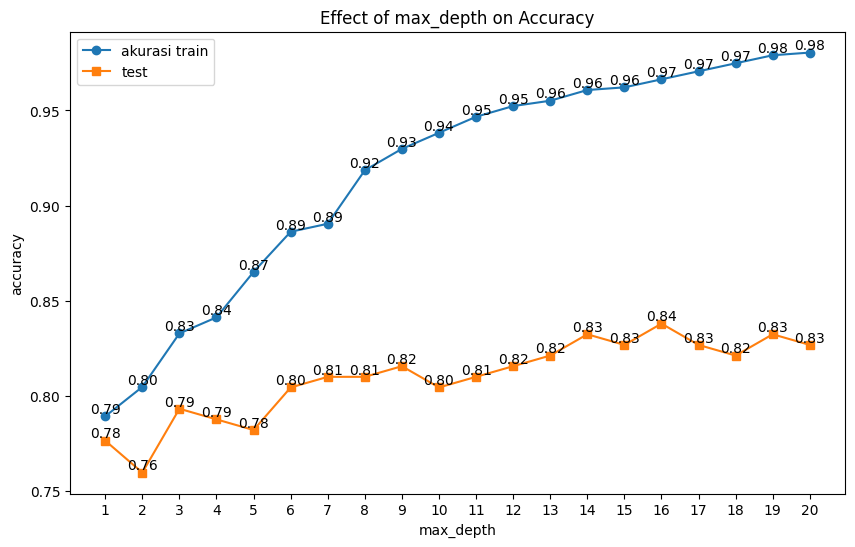

In [54]:
plt.figure(figsize=(10,6))
plt.plot(list(dep), acc_train, marker="o", label='akurasi train')
plt.plot(list(dep), acc_test,marker="s", label='test')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.xticks(list(dep))

for i, j in zip(list(dep), acc_train):
    plt.text(i, j, f'{j:.2f}', ha='center', va='bottom')
for i, j in zip(list(dep), acc_test):
    plt.text(i, j, f'{j:.2f}', ha='center', va='bottom')
plt.title('Effect of max_depth on Accuracy')

plt.legend()

best_depth = list(dep)[int(np.argmax(acc_test))]
print("max_depth dengan akurasi test terbaik:", best_depth,
      "(akurasi test =", round(max(acc_test), 2), ")")

**Interpretasi:**

Garis Biru (Akurasi Train):
  - Semakin besar nilai max_depth (kedalaman pohon), akurasi pada data pelatihan terus meningkat secara konsisten hingga mendekati sempurna (0.98 atau 98%). Hal ini karena model semakin kompleks dan menghafal detail data latihan.   
  
Garis Oranye (Akurasi Test):
  - Akurasi pada data uji awalnya naik dari max_depth 1 ke kisaran 0.83 - 0.84 (puncak terbaik berada di sekitar max_depth 14 atau 16).   
  - Namun, setelah melewati titik tertentu, akurasi data uji cenderung mendatar atau bahkan sedikit menurun meskipun kedalaman pohon terus ditambah.
  
Kesimpulan (Indikasi Overfitting):
  - Grafik ini menunjukkan gejala overfitting. Ketika max_depth dibuat terlalu tinggi (misalnya di atas 15), model menjadi terlalu rumit sehingga sangat bagus di data train, tetapi mulai kehilangan kemampuan generalisasinya pada data baru (test).
  - Kedalaman yang optimal untuk model ini adalah di sekitar angka 3 hingga 6 atau 14, di mana akurasi test mencapai titik tertinggi yang stabil tanpa membuat model terlalu kompleks

## Evaluate Best Model

In [56]:
best_dt = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
best_dt.fit(X_train, y_train)
y_pred_best = best_dt.predict(X_test)

print(f'Akurasi train: {best_dt.score(X_train, y_train):.2f}')
print(f'Akurasi test: {accuracy_score(y_test, y_pred):.2f}')

print("\n", classification_report(y_test, y_pred_best, target_names=["Tidak (0)", "Selamat (1)"]))

Akurasi train: 0.97
Akurasi test: 0.84

               precision    recall  f1-score   support

   Tidak (0)       0.85      0.89      0.87       110
 Selamat (1)       0.81      0.75      0.78        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



**Interpretasi:**

- Analisis Akurasi (Train vs Test):
  - Akurasi train mencapai 0.97 (97%), sedangkan akurasi test berada di angka 0.84 (84%).   
  - Adanya selisih yang cukup signifikan (13%) antara data latih dan data uji mengindikasikan bahwa model mengalami overfitting, di mana model sudah terlalu menghafal pola pada data latih sehingga sedikit kurang fleksibel saat menghadapi data baru (test).

- Performa Kelas "Tidak (0)" (Penumpang Tidak Selamat):
  - Precision (0.85): Dari seluruh penumpang yang diprediksi oleh model sebagai "Tidak", 85% di antaranya benar-benar tidak selamat.
   - Recall (0.89): Dari total 110 penumpang yang aslinya tidak selamat, model berhasil mendeteksi dan menjaring 89% dari mereka.
   - F1-score (0.87): Menunjukkan performa yang sangat baik dan tinggi dalam mengenali kelompok penumpang yang tidak selamat.
   
- Performa Kelas "Selamat (1)" (Penumpang Selamat):
  - Precision (0.81): Dari seluruh penumpang yang diprediksi selamat, 81% benar-benar selamat.
  - Recall (0.75): Dari total 69 penumpang yang aslinya selamat, model berhasil mengenali 75% di antaranya.
  - F1-score (0.78): Performa pada kelas ini sedikit lebih rendah dibandingkan kelas tidak selamat, namun tetap tergolong baik.
  
  
- Akurasi Keseluruhan dan Metrik Rata-rata:
  - Accuracy (0.84): Model berhasil membuat prediksi yang tepat secara keseluruhan pada 84% dari total 179 data pengujian.
  - Macro Avg & Weighted Avg: Nilai rata-rata macro (0.83) dan weighted (0.84) menunjukkan bahwa performa model secara umum sudah seimbang dan stabil dalam menangani kedua kelas kategori.
  
Kesimpulan Akhir:
- Model ini memiliki tingkat kemampuan tebak yang kuat (84% pada data uji), di mana model sangat handal dalam mendeteksi kelompok penumpang yang tidak selamat, meskipun ada sedikit catatan overfitting yang membuat performa pada data latih terlihat jauh lebih tinggi daripada data aslinya.

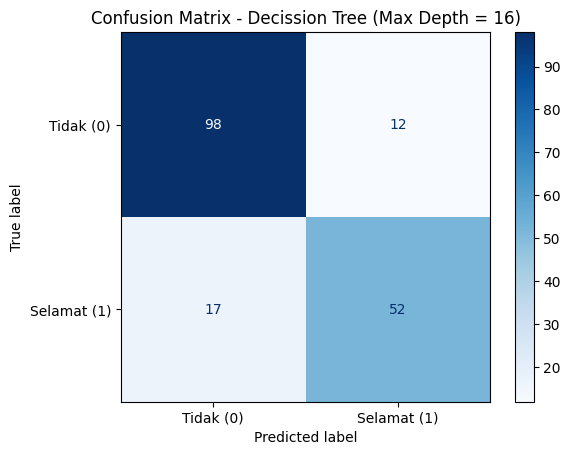

In [58]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_best),
                       display_labels=["Tidak (0)", "Selamat (1)"]).plot(cmap='Blues')
plt.title('Confusion Matrix - Decission Tree (Max Depth = 16)')
plt.show()

**Interpretasi:**

- True Negative (TN = 98): Model dengan benar memprediksi 98 penumpang sebagai "Tidak" (tidak selamat) dan aslinya memang tidak selamat.   
- False Positive (FP = 12): Terdapat 12 penumpang yang aslinya tidak selamat, namun salah diprediksi oleh model sebagai "Selamat".   
- False Negative (FN = 17): Terdapat 17 penumpang yang aslinya selamat, namun salah diprediksi oleh model sebagai "Tidak" (tidak selamat).   
- True Positive (TP = 52): Model dengan tepat memprediksi 52 penumpang sebagai "Selamat" dan aslinya memang selamat.   

Kesimpulan Utama:
- Model dengan kedalaman maksimal 16 ini menunjukkan performa yang sangat solid dan seimbang.
- Angka kesalahan prediksi (False Positive sebanyak 12 dan False Negative sebanyak 17) tergolong rendah, yang membuktikan bahwa model mampu mengenali kedua kelas (baik penumpang selamat maupun tidak selamat) dengan tingkat akurasi prediksi yang tinggi

### Feature Importance

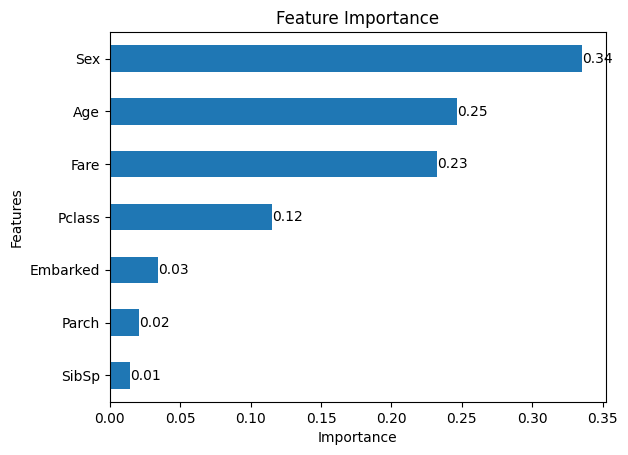

In [64]:
imp_sorted = pd.Series(best_dt.feature_importances_, index=X_train.columns).sort_values(ascending=True)
imp_sorted.plot(kind='barh')
plt.title('Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')
for i, val in enumerate(imp_sorted):
    plt.text(val, i, f'{val:.2f}', va='center', ha='left')
plt.show()

**Interpretasi:**

- **Fitur Paling Berpengaruh (`Sex` - 0.34):** Jenis kelamin adalah fitur paling penting untuk model. Hal ini sangat logis karena secara historis, prioritas evakuasi utama diberikan kepada perempuan.
- **Fitur Pendukung Utama (`Age` & `Fare` - 0.25 & 0.23):** Usia dan harga tiket (tarif) menempati posisi kedua dan ketiga. Faktor anak-anak balita yang didahulukan serta tingkat tarif tiket (yang berkolerasi dengan letak kabin di kapal) memberikan kontribusi besar pada keputusan model.
- **Fitur Kelas Sosial (`Pclass` - 0.12):** Kelas tiket juga merupakan faktor penting dalam menentukan keselamatan penumpang.
- **Fitur dengan Pengaruh Rendah (`Embarked`, `Parch`, `SibSp`):** Pelabuhan keberangkatan serta jumlah anggota keluarga di kapal memiliki kontribusi yang sangat kecil (< 4%) terhadap keputusan akhir model.

## Insight and Conclusion

Faktor Penentu Keselamatan (EDA):
  - Gender: Perempuan jauh lebih diprioritaskan dengan tingkat keselamatan mencapai 74%, sedangkan laki-laki hanya 19%.
  - Kelas Tiket: Penumpang Kelas 1 mendominasi keselamatan, sementara mayoritas penumpang Kelas 3 tidak selamat.
  - Usia: Balita (di bawah 5 tahun) mendapatkan prioritas utama penyelamatan.

Performa & Evaluasi Model (Decision Tree):
  - Model terbaik mencapai akurasi uji 84% (dengan max_depth optimal).
  - Sangat kuat dalam mendeteksi korban tidak selamat (Recall 89%).
  - Penambahan kedalaman pohon yang berlebihan (max_depth terlalu tinggi) memicu gejala overfitting (akurasi latih 97% vs uji 84%).

Kontribusi Fitur (Feature Importance):
  - Faktor penentu utama secara berurutan adalah Jenis Kelamin (Sex), Usia (Age), Harga Tiket (Fare), dan Kelas Tiket (Pclass).

Kesimpulan Akhir:
  - Algoritma Decision Tree sangat ideal untuk dataset ini karena mencerminkan aturan evakuasi dunia nyata ("wanita, anak-anak, dan kelas atas didahulukan") secara akurat dan mudah diinterpretasikan.